In [1]:
%pip install tensorflow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [18]:
# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Define class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Display dataset shape
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# Select only two classes: Cat and Dog
train_mask = (y_train.flatten() == 3) | (y_train.flatten() == 5)
test_mask = (y_test.flatten() == 3) | (y_test.flatten() == 5)

x_train = x_train[train_mask]
y_train = y_train[train_mask]

x_test = x_test[test_mask]
y_test = y_test[test_mask]

# Convert labels: Cat = 0, Dog = 1
y_train = (y_train.flatten() == 5).astype("int32")
y_test = (y_test.flatten() == 5).astype("int32")

print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)

Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)
Training Images: (10000, 32, 32, 3)
Testing Images: (2000, 32, 32, 3)


In [4]:
# Load pre-trained MobileNetV2
base_model = keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

print("Pre-trained Model Loaded Successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Pre-trained Model Loaded Successfully!


In [5]:
# Freeze pre-trained model
base_model.trainable = False

print("Pre-trained layers are frozen!")

Pre-trained layers are frozen!


In [6]:
# Create new model
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Resizing(96, 96),

    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resizing (Resizing)                  │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_96 (Functional)     │ (None, 3, 3, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 27s 89ms/step - accuracy: 0.8440 - loss: 0.3597 - val_accuracy: 0.8510 - val_loss: 0.3246
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 85ms/step - accuracy: 0.8916 - loss: 0.2647 - val_accuracy: 0.8805 - val_loss: 0.2858
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 85ms/step - accuracy: 0.9096 - loss: 0.2171 - val_accuracy: 0.8675 - val_loss: 0.3027
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 86ms/step - accuracy: 0.9306 - loss: 0.1732 - val_accuracy: 0.8725 - val_loss: 0.2945
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 86ms/step - accuracy: 0.9517 - loss: 0.1291 - val_accuracy: 0.8685 - val_loss: 0.3022


In [10]:
# Unfreeze the base model
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Compile with low learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train again
history_fine = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 35s 107ms/step - accuracy: 0.8631 - loss: 0.3446 - val_accuracy: 0.8625 - val_loss: 0.3236
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 28s 114ms/step - accuracy: 0.8994 - loss: 0.2421 - val_accuracy: 0.8685 - val_loss: 0.3129
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 24s 94ms/step - accuracy: 0.9168 - loss: 0.2029 - val_accuracy: 0.8665 - val_loss: 0.3037


In [14]:
# Evaluate using testing data
test_loss, test_accuracy = model.evaluate(x_test, y_test)

# Display results
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.8600 - loss: 0.3458
Test Loss: 0.34576332569122314
Test Accuracy: 86.00000143051147 %


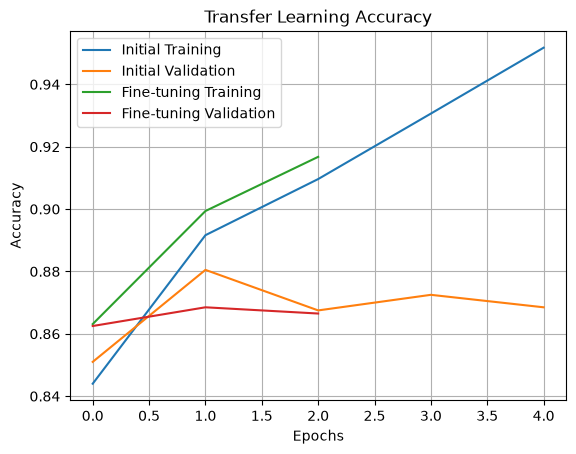

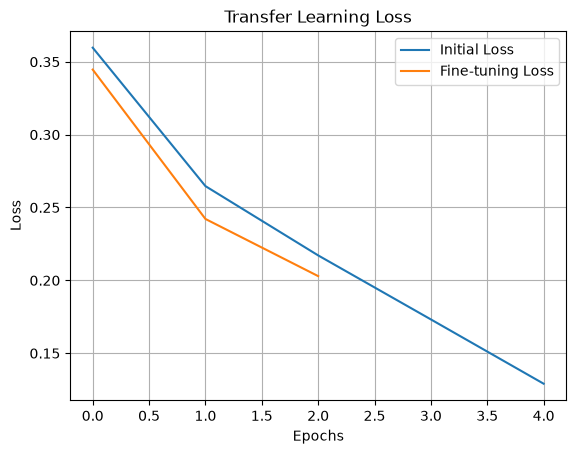

In [15]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Initial Training')
plt.plot(history.history['val_accuracy'], label='Initial Validation')

plt.plot(history_fine.history['accuracy'], label='Fine-tuning Training')
plt.plot(history_fine.history['val_accuracy'], label='Fine-tuning Validation')

plt.title("Transfer Learning Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Plot training loss
plt.plot(history.history['loss'], label='Initial Loss')
plt.plot(history_fine.history['loss'], label='Fine-tuning Loss')

plt.title("Transfer Learning Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [19]:
# Predict first 10 testing images
predictions = model.predict(x_test[:10])

# Get predicted class indexes
predicted_labels = np.argmax(predictions, axis=1)

# Display actual and predicted labels
for i in range(10):
    print(
        "Actual:", class_names[y_test[i]],
        "| Predicted:", class_names[predicted_labels[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Actual: Airplane | Predicted: Airplane
Actual: Airplane | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Automobile | Predicted: Airplane
Actual: Airplane | Predicted: Airplane


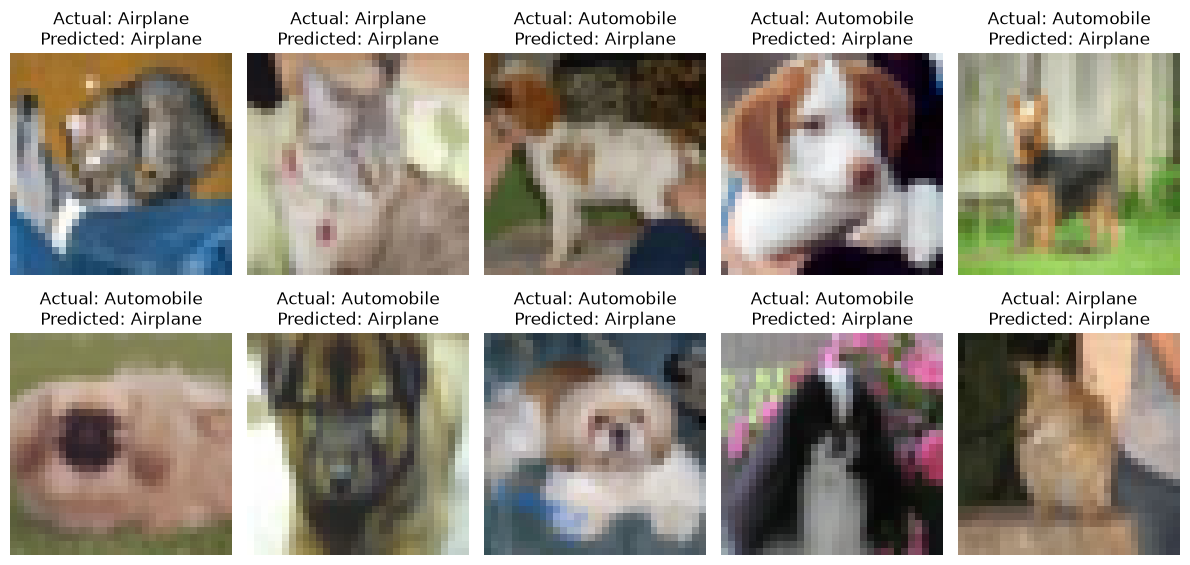

In [21]:
# Display predicted images
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_test[i].astype('uint8'))

    # Display actual and predicted labels
    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[predicted_labels[i]]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()